<a href="https://colab.research.google.com/github/christiana-adisa/Applied-ML-at-Scale/blob/main/Data_Indexing_to_Matric_Factorization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit, prange

In [3]:
# MAP users to index
ratings = np.loadtxt("/content/drive/MyDrive/ml-32m/ml-32m/ratings.csv", delimiter=",", dtype= None, encoding='utf-8', skiprows=1)
# np.loadtxt("/content/drive/MyDrive/ml-32m/ml-32m/movies.csv", delimiter=",", dtype= None, encoding='utf-8', skiprows=1)
# np.loadtxt("/content/drive/MyDrive/ml-32m/ml-32m/.csv", delimiter=",", dtype= None, encoding='utf-8', skiprows=1)
mini_ratings = ratings[:1000000]
ratings_row = mini_ratings[:,0]
ratings_row

array([1.000e+00, 1.000e+00, 1.000e+00, ..., 6.502e+03, 6.502e+03,
       6.503e+03])

In [4]:
# rating.userId.nunique()

Pratical One - Data Indexing

In [5]:
# MAP user to index and vice versa
user_dict = {}
index_user_list = []

for user_id in ratings_row:
  if user_id not in user_dict:

    next_index= len(index_user_list)

    user_dict[user_id] = next_index

    index_user_list.append(user_id)

In [6]:
# MAP items to index
# ratings_item = np.loadtxt("/content/drive/MyDrive/ml-32m/ml-32m/ratings.csv", delimiter=",", dtype= None, encoding='utf-8', skiprows=1)
ratings_col = mini_ratings[:, 1]

print(ratings_col)

item_dict = {}
index_item_list = []

for i, item_id in enumerate(ratings_col):
  if item_id not in item_dict:

    next_item_index = len(index_item_list)

    item_dict[item_id] = next_item_index

    index_item_list.append(item_id)

[  17.   25.   29. ... 3952. 3968.  110.]


In [7]:
# index_item_list[:10]

In [8]:
index_user_list[:10]

[np.float64(1.0),
 np.float64(2.0),
 np.float64(3.0),
 np.float64(4.0),
 np.float64(5.0),
 np.float64(6.0),
 np.float64(7.0),
 np.float64(8.0),
 np.float64(9.0),
 np.float64(10.0)]

In [9]:
# for user_id in index_user_list:
#   print(user_id)

In [10]:
# index_item_list[:10]

In [ ]:
# Next thing is to create the structure that index the data by user (Sparse Matrix)
# data_by_user = [[(0,4)],[(1,3),(0,5)]] where the first list is the index of the user, it goes to the index_user_list and retrive the user in that index,
# it then goes to retrive the value in the dict using the user gotten from index_user_list, it append that value to a tuple. After, it uses that value gotten, first append it to a tuple,
# there into the index_item_list to retrive
# the item using the index and use that item in the rating csv to retrive the corresponding rating for that movie

In [ ]:
# data_by_user = [[] for _ in range(len(index_user_list))]

# for user_id in index_user_list:
#   user_index = user_dict[user_id] #0
#   if index_item_list[user_index] in item_dict:
#     item_index = index_item_list[user_index] #1

#     data_by_user[user_index].append((item_index, ratings[2]))


In [11]:
# Split data into train and test set

import random

data_by_user_train = [[] for _ in range(len(index_user_list))]
data_by_user_test = [[] for _ in range(len(index_user_list))]

data_by_item_train = [[] for _ in range(len(index_item_list))]
data_by_item_test = [[] for _ in range(len(index_item_list))]

data_by_user = [[] for _ in range(len(index_user_list))]
data_by_item = [[] for _ in range(len(index_item_list))]
# 0  1  17  4.0
# 2  1  29  4.0

cut_off = 0.8

for row in mini_ratings:
    random_num = random.random()

    user_id = row[0]
    item_id = row[1]
    rating = float(row[2])

    if user_id in user_dict and item_id in item_dict:
        u_idx = user_dict[user_id]
        i_idx =  item_dict[item_id]

        data_by_user[u_idx].append((i_idx, rating))
        data_by_item[i_idx].append((u_idx, rating))

        if random_num < cut_off:
          data_by_user_train[u_idx].append((i_idx, rating))
          data_by_item_train[i_idx].append((u_idx, rating))
        else:
          data_by_user_test[u_idx].append((i_idx, rating))
          data_by_item_test[i_idx].append((u_idx, rating))


    else:
        print("Something is wrong!!!")

print(data_by_user[:100])

[[(0, 4.0), (1, 1.0), (2, 2.0), (3, 5.0), (4, 5.0), (5, 2.0), (6, 1.0), (7, 5.0), (8, 3.0), (9, 5.0), (10, 1.0), (11, 5.0), (12, 4.0), (13, 3.0), (14, 5.0), (15, 5.0), (16, 4.0), (17, 5.0), (18, 5.0), (19, 4.0), (20, 1.0), (21, 2.0), (22, 3.0), (23, 5.0), (24, 5.0), (25, 3.0), (26, 2.0), (27, 4.0), (28, 4.0), (29, 3.0), (30, 5.0), (31, 5.0), (32, 5.0), (33, 2.0), (34, 5.0), (35, 4.0), (36, 5.0), (37, 5.0), (38, 5.0), (39, 5.0), (40, 3.0), (41, 5.0), (42, 5.0), (43, 2.0), (44, 1.0), (45, 5.0), (46, 4.0), (47, 1.0), (48, 1.0), (49, 4.0), (50, 3.0), (51, 4.0), (52, 4.0), (53, 5.0), (54, 1.0), (55, 2.0), (56, 5.0), (57, 5.0), (58, 1.0), (59, 5.0), (60, 2.0), (61, 2.0), (62, 5.0), (63, 5.0), (64, 5.0), (65, 4.0), (66, 5.0), (67, 5.0), (68, 5.0), (69, 4.0), (70, 1.0), (71, 5.0), (72, 4.0), (73, 4.0), (74, 5.0), (75, 5.0), (76, 5.0), (77, 3.0), (78, 4.0), (79, 3.0), (80, 5.0), (81, 3.0), (82, 1.0), (83, 4.0), (84, 2.0), (85, 4.0), (86, 5.0), (87, 5.0), (88, 5.0), (89, 5.0), (90, 1.0), (91, 3.

In [12]:
# data_by_user_train[0]

[(0, 4.0),
 (1, 1.0),
 (3, 5.0),
 (4, 5.0),
 (5, 2.0),
 (6, 1.0),
 (7, 5.0),
 (8, 3.0),
 (9, 5.0),
 (11, 5.0),
 (12, 4.0),
 (13, 3.0),
 (14, 5.0),
 (17, 5.0),
 (18, 5.0),
 (19, 4.0),
 (20, 1.0),
 (21, 2.0),
 (22, 3.0),
 (23, 5.0),
 (24, 5.0),
 (26, 2.0),
 (27, 4.0),
 (28, 4.0),
 (29, 3.0),
 (30, 5.0),
 (32, 5.0),
 (33, 2.0),
 (35, 4.0),
 (37, 5.0),
 (38, 5.0),
 (39, 5.0),
 (40, 3.0),
 (41, 5.0),
 (42, 5.0),
 (43, 2.0),
 (44, 1.0),
 (45, 5.0),
 (46, 4.0),
 (48, 1.0),
 (49, 4.0),
 (50, 3.0),
 (51, 4.0),
 (52, 4.0),
 (54, 1.0),
 (55, 2.0),
 (56, 5.0),
 (57, 5.0),
 (58, 1.0),
 (59, 5.0),
 (60, 2.0),
 (61, 2.0),
 (62, 5.0),
 (63, 5.0),
 (64, 5.0),
 (66, 5.0),
 (67, 5.0),
 (68, 5.0),
 (69, 4.0),
 (70, 1.0),
 (72, 4.0),
 (73, 4.0),
 (74, 5.0),
 (75, 5.0),
 (76, 5.0),
 (77, 3.0),
 (78, 4.0),
 (79, 3.0),
 (81, 3.0),
 (82, 1.0),
 (83, 4.0),
 (84, 2.0),
 (85, 4.0),
 (86, 5.0),
 (88, 5.0),
 (89, 5.0),
 (90, 1.0),
 (91, 3.0),
 (92, 4.0),
 (93, 2.0),
 (95, 2.0),
 (96, 4.0),
 (98, 1.0),
 (99, 3.0),
 

In [14]:
print(len(data_by_user))
print(len(data_by_item))

6503
26505


In [15]:
# data_by_user[0]

In [16]:
# data_by_item[0]

Plot Ploting for data/ Power Law Distribution

In [17]:
# data_by_user[0]

In [18]:
# data_by_item[0]

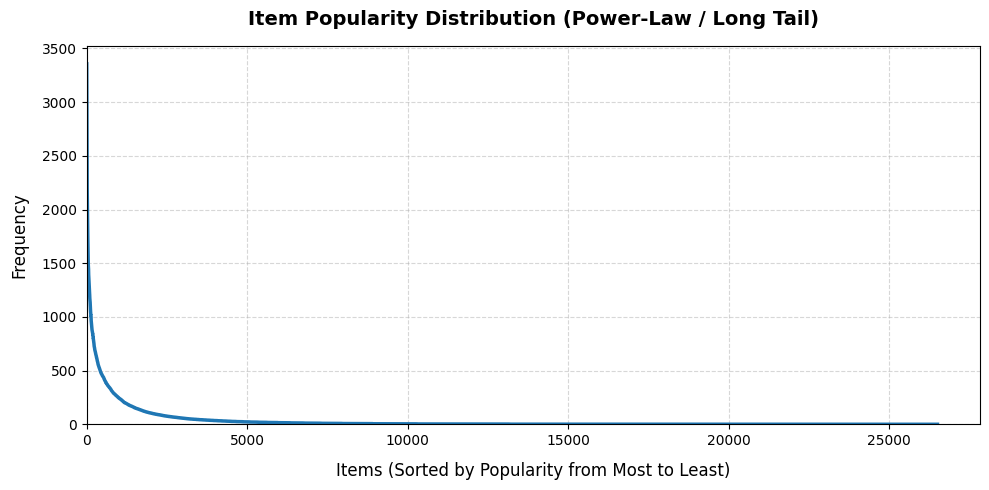

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

item_counts = Counter()
for user_ratings in data_by_user:
  for item_idx, rating in user_ratings:
    item_counts[item_idx] += 1

frequencies = sorted(item_counts.values(), reverse=True)
total_items = len(index_item_list)
if len(frequencies) < total_items:
  zero_padding = [0] * (total_items - len(frequencies))
  frequencies.extend(zero_padding)

plt.figure(figsize=(10, 5))

plt.plot(np.arange(len(frequencies)), frequencies, linewidth=2.5, label='Item Popularity')

plt.title(
    'Item Popularity Distribution (Power-Law / Long Tail)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Items (Sorted by Popularity from Most to Least)', fontsize=12, labelpad=10)
plt.ylabel('Frequency', fontsize=12, labelpad=10)

plt.xlim(left=0)
plt.ylim(bottom=0)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save as SVG and PDF
plt.savefig('power_plot.svg', format='svg', bbox_inches='tight')
plt.savefig('power_plot.pdf', format='pdf', bbox_inches='tight')

plt.show()


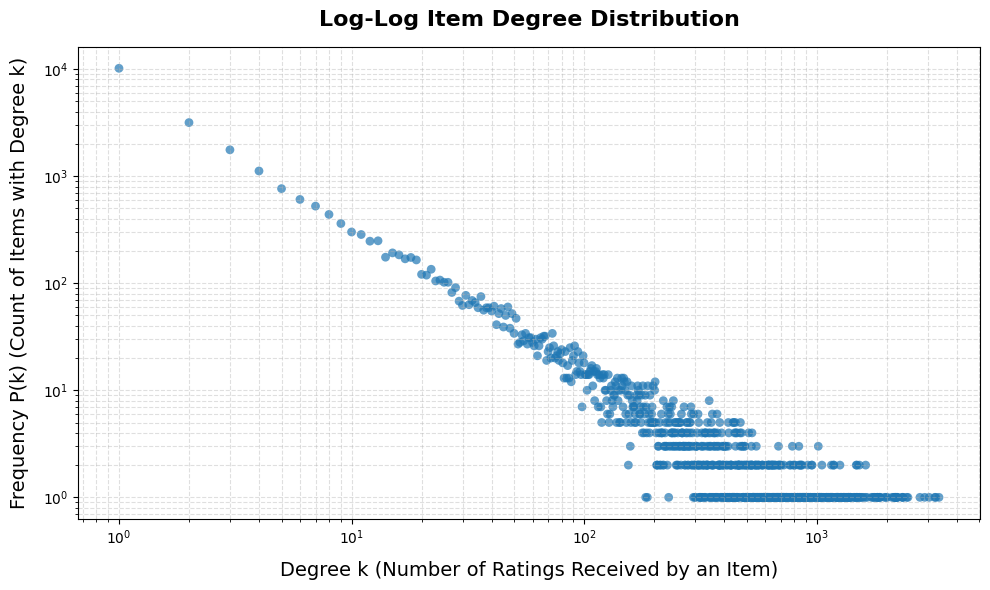

In [23]:
from collections import Counter

item_counts = Counter()
for user_ratings in data_by_user:
    for item_idx, rating in user_ratings:
        item_counts[item_idx] += 1

for item_idx in range(len(index_item_list)):
    if item_idx not in item_counts:
        item_counts[item_idx] = 0


degree_counts = Counter(item_counts.values())

degrees_k = sorted(degree_counts.keys())
frequencies_pk = [degree_counts[k] for k in degrees_k]

plt.figure(figsize=(10, 6))

plt.scatter(degrees_k, frequencies_pk, alpha=0.7, edgecolors='none', s=40, label='Data Points')

plt.xscale('log')
plt.yscale('log')

plt.title('Log-Log Item Degree Distribution', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Degree k (Number of Ratings Received by an Item)', fontsize=14, labelpad=10)
plt.ylabel('Frequency P(k) (Count of Items with Degree k)', fontsize=14, labelpad=10)
plt.grid(True, which="both", linestyle='--', alpha=0.4)

plt.tight_layout()

plt.savefig('log_log_item.svg', format='svg', bbox_inches='tight')
plt.show()

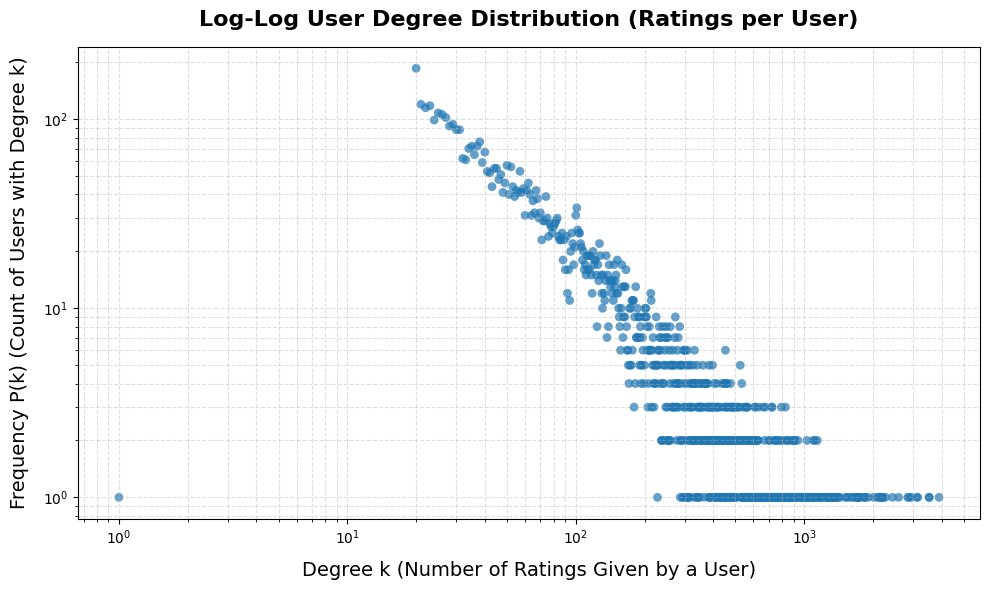

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter


user_degrees = [len(user_ratings) for user_ratings in data_by_user]


degree_counts = Counter(user_degrees)

degrees_k = sorted(degree_counts.keys())
frequencies_pk = [degree_counts[k] for k in degrees_k]

plt.figure(figsize=(10, 6))

plt.scatter(degrees_k, frequencies_pk, alpha=0.7, edgecolors='none', s=40, label='Users')

plt.xscale('log')
plt.yscale('log')

plt.title('Log-Log User Degree Distribution (Ratings per User)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Degree k (Number of Ratings Given by a User)', fontsize=14, labelpad=10)
plt.ylabel('Frequency P(k) (Count of Users with Degree k)', fontsize=14, labelpad=10)
plt.grid(True, which="both", linestyle='--', alpha=0.4)

plt.tight_layout()

plt.savefig('log_log_user.svg', format='svg', bbox_inches='tight')
plt.show()


Spilting the Dataset to Training and Testing set

Model Building - Meximum likelihood estimate using Alternating Least Squares

Biases Only

In [25]:
len(data_by_user_train)

6503

In [26]:
len(data_by_user_train[0])

118

In [27]:
train_rating = 0
for i in data_by_user_train:
  train_rating += len(i)
print(train_rating)

test_rating = 0
for i in data_by_user_test:
  test_rating += len(i)
print(test_rating)

800134
199866


In [30]:
lambda_val = 1.5
gamma_val = 0.1

rmse_train_list = []
rmse_test_list = []

rmse_list = []
loss_train_func = []
loss_test_func = []

M = len(data_by_user_train)
N = len(data_by_item_train)

user_biases = np.zeros(M)
item_biases = np.zeros(N)

epochs = 10

for epoch in range(epochs):
  for i in range(M):
    bias = 0
    item_counter = 0
    for (n,r) in data_by_user_train[i]:
      bias += lambda_val * (r - item_biases[n])
      item_counter += 1
    bias = bias / (lambda_val * item_counter + gamma_val)
    user_biases[i] = bias

    # print(i)

  for i in range((N)):
    bias = 0
    item_counter = 0
    for (n,r) in data_by_item_train[i]:
      bias += lambda_val * (r - user_biases[n])
      item_counter += 1
    bias = bias / (lambda_val * item_counter + gamma_val)
    item_biases[i] = bias

  train_user_error = 0
  for i in range(M):
    for (n,r) in data_by_user_train[i]:
      train_user_error += (r - user_biases[i] - item_biases[n])**2
    user_train_loss = (((lambda_val/2) * train_user_error) + ((gamma_val/2) * np.sum(user_biases**2)) + ((gamma_val/2) * np.sum(item_biases**2)))

  test_user_error = 0
  for i in range(M):
    for (n,r) in data_by_user_test[i]:
      test_user_error += (r - user_biases[i] - item_biases[n])**2
    # user_test_loss = (((lambda_val/2) * test_user_error) + ((gamma_val/2) * np.sum(user_biases**2)) + ((gamma_val/2) * np.sum(item_biases**2)))

  # print(user_train_loss)
  loss_train_func.append(user_train_loss)


  # print(user_test_loss)
  # loss_test_func.append(user_test_loss)

  # This is the root mean square for my train and test set
  rmse_train = (train_user_error/train_rating)**0.5
  rmse_test = (test_user_error/test_rating)**0.5


  rmse_train_list.append(rmse_train)
  rmse_test_list.append(rmse_test)
  # print(rmse_train)
  # print(rmse_test)
  print(f"Epochs {epoch+1} | Loss: {user_train_loss: .4f} | RMSE Train: {rmse_train: .3f} | RMSE Test: {rmse_test :.3f}")


# print(loss_func)
# print(rmse_list)

Epochs 1 | Loss:  440467.5857 | RMSE Train:  0.852 | RMSE Test: 0.884
Epochs 2 | Loss:  425730.4158 | RMSE Train:  0.837 | RMSE Test: 0.871
Epochs 3 | Loss:  424862.9867 | RMSE Train:  0.836 | RMSE Test: 0.871
Epochs 4 | Loss:  424780.2578 | RMSE Train:  0.836 | RMSE Test: 0.871
Epochs 5 | Loss:  424763.1843 | RMSE Train:  0.836 | RMSE Test: 0.871
Epochs 6 | Loss:  424754.4155 | RMSE Train:  0.836 | RMSE Test: 0.871
Epochs 7 | Loss:  424747.1160 | RMSE Train:  0.836 | RMSE Test: 0.871
Epochs 8 | Loss:  424740.1448 | RMSE Train:  0.836 | RMSE Test: 0.871
Epochs 9 | Loss:  424733.2727 | RMSE Train:  0.836 | RMSE Test: 0.871
Epochs 10 | Loss:  424726.4495 | RMSE Train:  0.836 | RMSE Test: 0.871


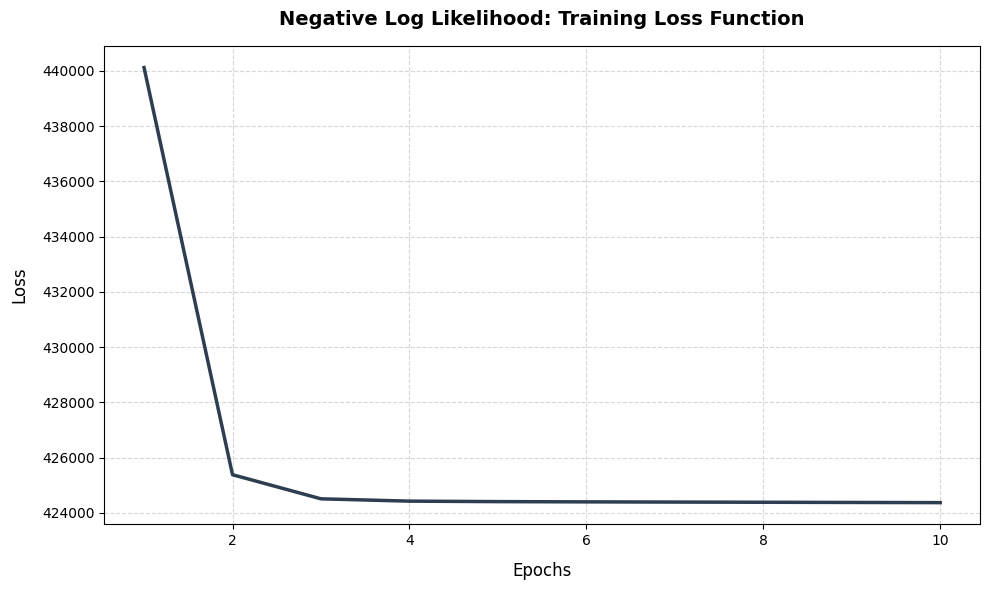

In [ ]:
# Ploting the loss function
iterations = range(1, epochs + 1)

plt.figure(figsize=(10, 6))

plt.plot(iterations, loss_train_func, color='#2C3E50', linewidth=2.5, label='Training Loss')


plt.grid(True, linestyle='--', alpha=0.5)

plt.title('Negative Log Likelihood: Training Loss Function', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Epochs', fontsize=14, labelpad=10)
plt.ylabel('Loss', fontsize=14, labelpad=10)
plt.tight_layout()


plt.show()

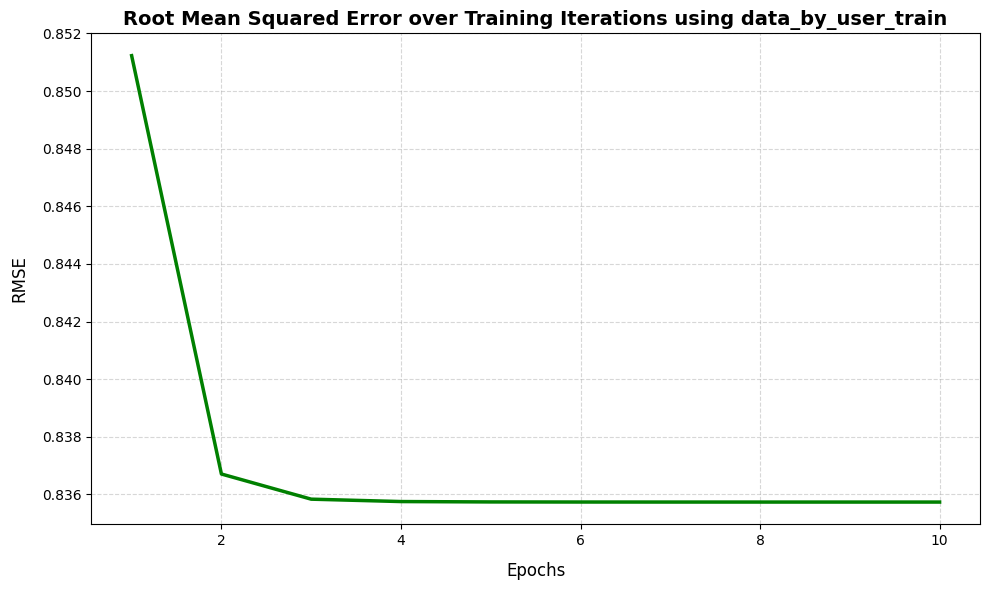

In [ ]:
# Plotting the root mean squared error over data_by_user_train
plt.figure(figsize=(10,6))

plt.plot(iterations, rmse_train_list, color='g', linewidth=2.5)

plt.grid(True, linestyle='--', alpha=0.5)
plt.title("Root Mean Squared Error over Training Iterations using data_by_user_train", fontsize=16, fontweight="bold")
plt.xlabel("Epochs", fontsize=14, labelpad=10)
plt.ylabel("RMSE", fontsize=14, labelpad=10)

plt.tight_layout()
plt.show()


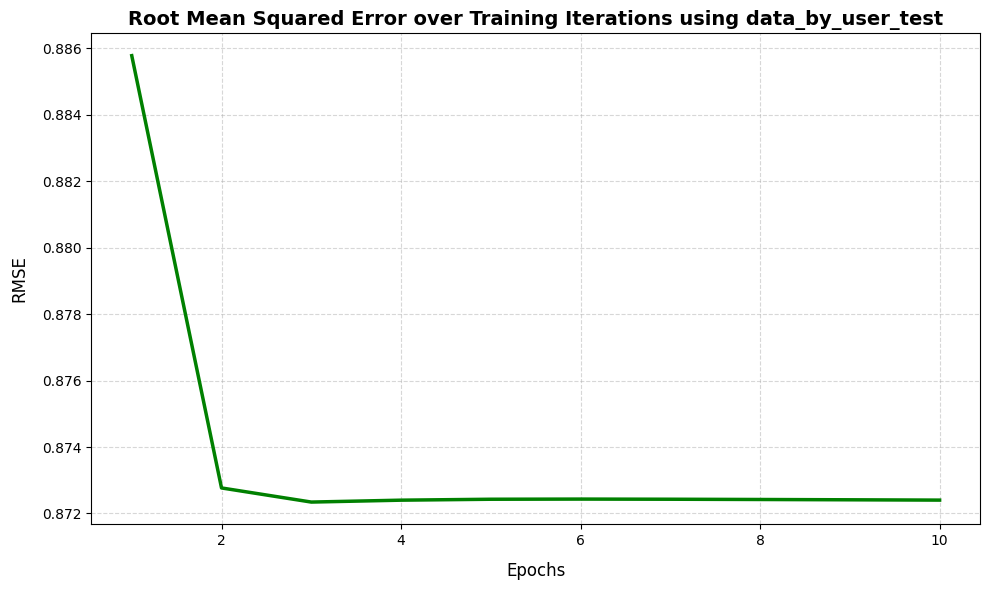

In [ ]:
# Plotting the root mean squared error over data_by_user_test
plt.figure(figsize=(10,6))

plt.plot(iterations, rmse_test_list, color='g', linewidth=2.5)

plt.grid(True, linestyle='--', alpha=0.5)
plt.title("Root Mean Squared Error over Training Iterations using data_by_user_test", fontsize=16, fontweight="bold")
plt.xlabel("Epochs", fontsize=14, labelpad=10)
plt.ylabel("RMSE", fontsize=14, labelpad=10)

plt.tight_layout()
plt.show()

In [ ]:
# user_biases**2

Practical 3
Building Model with Embeddings


In [ ]:
mean = 0
variance = 1

U = np.random.normal(mean, (variance**0.5), size=(M, 23))
# U_transpose = U.transpose()
# V = np.random.normal(mean, (variance**0.5), size=(N, 23))

In [34]:
mean = 0
variance = 1
k= 5

U = np.random.normal(mean, (variance**0.5), size=(M, k))
# U_transpose = U.transpose()
V = np.random.normal(mean, (variance**0.5), size=(N, k))


lambda_val = 0.5 #precision parameter.  try different values
gamma_val = 0.1 #bias regularizer. try different values
tau_val = 5 #vector regularizer. try different values

rmse_train_list = []
rmse_test_list = []

rmse_list = []
loss_train_func = []
loss_test_func = []

M = len(data_by_user_train)
N = len(data_by_item_train)

user_biases = np.zeros(M)
item_biases = np.zeros(N)

epochs = 10

for epoch in range(epochs):
  for i in range(M):
    bias = 0
    item_counter = 0
    for (n,r) in data_by_user_train[i]:
      bias += lambda_val * (r - (np.dot(U[i], V[n]) + item_biases[n]))
      item_counter += 1
    bias = bias / (lambda_val * item_counter + gamma_val)
    user_biases[i] = bias

    #     updating user vector
    # user_vector = np.zeros(k)
    v_squared = np.zeros((k,k))
    v_sum_biases = np.zeros(k)
    for (n,r) in data_by_user_train[i]:
      v_squared += np.outer(V[n], V[n])
      v_sum_biases += V[n] * (r - user_biases[i] - item_biases[n])

    user_vector = np.linalg.inv(lambda_val * v_squared + tau_val*np.identity(k)) @ (lambda_val  * v_sum_biases)
    U[i] = user_vector


  for i in range((N)):
    bias = 0
    item_counter = 0
    for (n,r) in data_by_item_train[i]:
      bias += lambda_val * (r - (np.dot(U[n], V[i]) + user_biases[n]))
      item_counter += 1
    bias = bias / (lambda_val * item_counter + gamma_val)
    item_biases[i] = bias

    # undating item vector
    u_squared = np.zeros((k,k))
    u_sum_biases = np.zeros(k)
    for (n,r) in data_by_item_train[i]:
      u_squared += np.outer(U[n], U[n])
      u_sum_biases += U[n] * (r - user_biases[n] - item_biases[i])
    item_vector = np.linalg.inv(lambda_val * u_squared + tau_val*np.identity(k)) @ (lambda_val  * u_sum_biases)
    V[i] = item_vector

  train_user_error = 0
  for i in range(M):
    for (n,r) in data_by_user_train[i]:
      train_user_error += (r - np.dot(U[i], V[n]) -  user_biases[i] - item_biases[n])**2
  user_train_loss = (((lambda_val/2) * train_user_error) + ((tau_val/2)* np.sum(np.dot(U[i],U[i]))) + ((tau_val/2)* np.sum(np.dot(V[i],V[i]))) +  ((gamma_val/2) * np.sum(user_biases**2)) + ((gamma_val/2) * np.sum(item_biases**2)))

  test_user_error = 0
  for i in range(M):
    for (n,r) in data_by_user_test[i]:
      test_user_error += (r - np.dot(U[i], V[n]) - user_biases[i] - item_biases[n])**2
    # user_test_loss = (((lambda_val/2) * test_user_error) + ((gamma_val/2) * np.sum(user_biases**2)) + ((gamma_val/2) * np.sum(item_biases**2)))

  # print(user_train_loss)
  loss_train_func.append(user_train_loss)


  # print(user_test_loss)
  # loss_test_func.append(user_test_loss)

  # This is the root mean square for my train and test set
  rmse_train = (train_user_error/train_rating)**0.5
  rmse_test = (test_user_error/test_rating)**0.5


  print(f"Epochs {epoch+1} | Loss: {user_train_loss: .4f} | RMSE Train: {rmse_train: .3f} | RMSE Test: {rmse_test :.3f}")

  # rmse_test = (test_user_error/test_rating)**0.5


  rmse_train_list.append(rmse_train)
  rmse_test_list.append(rmse_test)
  # print(rmse_train)
  # print(rmse_test)


# print(loss_func)
# print(rmse_list)

Epochs 1 | Loss:  154033.2250 | RMSE Train:  0.863 | RMSE Test: 0.906
Epochs 2 | Loss:  130738.9470 | RMSE Train:  0.793 | RMSE Test: 0.856
Epochs 3 | Loss:  122715.0064 | RMSE Train:  0.767 | RMSE Test: 0.840
Epochs 4 | Loss:  119222.7702 | RMSE Train:  0.756 | RMSE Test: 0.832
Epochs 5 | Loss:  117597.4926 | RMSE Train:  0.751 | RMSE Test: 0.829
Epochs 6 | Loss:  116791.2539 | RMSE Train:  0.748 | RMSE Test: 0.827
Epochs 7 | Loss:  116355.8980 | RMSE Train:  0.747 | RMSE Test: 0.827
Epochs 8 | Loss:  116099.6805 | RMSE Train:  0.746 | RMSE Test: 0.826
Epochs 9 | Loss:  115936.5287 | RMSE Train:  0.745 | RMSE Test: 0.826
Epochs 10 | Loss:  115825.5584 | RMSE Train:  0.745 | RMSE Test: 0.826


In [ ]:
# I used this block of code to find the best hyperparameters for my model
# import itertools

# k_grid = [5, 10]
# lambda_grid = [0.5, 1.0, 1.5]
# tau_grid = [0.1, 1.0, 5.0]
# gamma_grid = [0.1, 1.0, 5.0]

# best_test_rmse = float('inf')
# best_params = {}

# sweep_epochs = 3

# print("Starting Hyperparameter Grid Search...\n")

# for k_val, l_val, t_val, g_val in itertools.product(k_grid, lambda_grid, tau_grid, gamma_grid):
#     # Initialize parameters for this run
#     U_sweep = np.random.normal(0, 1.0, size=(M, k_val))
#     V_sweep = np.random.normal(0, 1.0, size=(N, k_val))
#     user_biases_sweep = np.zeros(M)
#     item_biases_sweep = np.zeros(N)

#     for epoch in range(sweep_epochs):
#         # Update Users
#         for i in range(M):
#             bias = 0
#             item_counter = 0
#             for (n, r) in data_by_user_train[i]:
#                 bias += l_val * (r - (np.dot(U_sweep[i], V_sweep[n]) + item_biases_sweep[n]))
#                 item_counter += 1
#             if item_counter > 0:
#                 user_biases_sweep[i] = bias / (l_val * item_counter + g_val)

#             v_squared = np.zeros((k_val, k_val))
#             v_sum_biases = np.zeros(k_val)
#             for (n, r) in data_by_user_train[i]:
#                 v_squared += np.outer(V_sweep[n], V_sweep[n])
#                 v_sum_biases += V_sweep[n] * (r - user_biases_sweep[i] - item_biases_sweep[n])
#             U_sweep[i] = np.linalg.inv(l_val * v_squared + t_val * np.identity(k_val)) @ (l_val * v_sum_biases)

#         # Update Items
#         for i in range(N):
#             bias = 0
#             item_counter = 0
#             for (n, r) in data_by_item_train[i]:
#                 bias += l_val * (r - (np.dot(U_sweep[n], V_sweep[i]) + user_biases_sweep[n]))
#                 item_counter += 1
#             if item_counter > 0:
#                 item_biases_sweep[i] = bias / (l_val * item_counter + g_val)

#             u_squared = np.zeros((k_val, k_val))
#             u_sum_biases = np.zeros(k_val)
#             for (n, r) in data_by_item_train[i]:
#                 u_squared += np.outer(U_sweep[n], U_sweep[n])
#                 u_sum_biases += U_sweep[n] * (r - user_biases_sweep[n] - item_biases_sweep[i])
#             V_sweep[i] = np.linalg.inv(l_val * u_squared + t_val * np.identity(k_val)) @ (l_val * u_sum_biases)

#     # Evaluate current run
#     train_err = 0
#     for i in range(M):
#         for (n, r) in data_by_user_train[i]:
#             train_err += (r - np.dot(U_sweep[i], V_sweep[n]) - user_biases_sweep[i] - item_biases_sweep[n])**2

#     test_err = 0
#     for i in range(M):
#         for (n, r) in data_by_user_test[i]:
#             test_err += (r - np.dot(U_sweep[i], V_sweep[n]) - user_biases_sweep[i] - item_biases_sweep[n])**2

#     rmse_train = (train_err / train_rating)**0.5
#     rmse_test = (test_err / test_rating)**0.5

#     print(f"Params -> k: {k_val}, lambda: {l_val:.2f}, tau: {t_val:.2f}, gamma: {g_val:.2f} | Train RMSE: {rmse_train:.4f} | Test RMSE: {rmse_test:.4f}")

#     if rmse_test < best_test_rmse:
#         best_test_rmse = rmse_test
#         best_params = {'k': k_val, 'lambda': l_val, 'tau': t_val, 'gamma': g_val}

# print("\n=== Best Hyperparameters Found ===")
# print(f"Best Test RMSE: {best_test_rmse:.4f}")
# print(best_params)

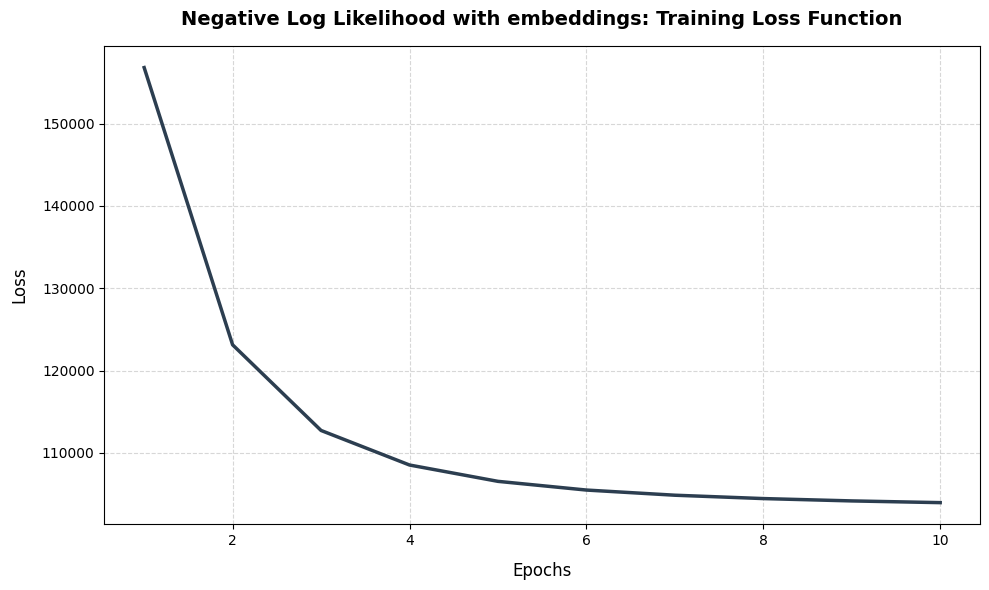

In [33]:
# Ploting the loss function with Embeddings
iterations = range(1, epochs + 1)

plt.figure(figsize=(10, 6))

plt.plot(iterations, loss_train_func, color='#2C3E50', linewidth=2.5, label='Training Loss')


plt.grid(True, linestyle='--', alpha=0.5)

plt.title('Negative Log Likelihood with embeddings: Training Loss Function', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Epochs', fontsize=12, labelpad=10)
plt.ylabel('Loss', fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

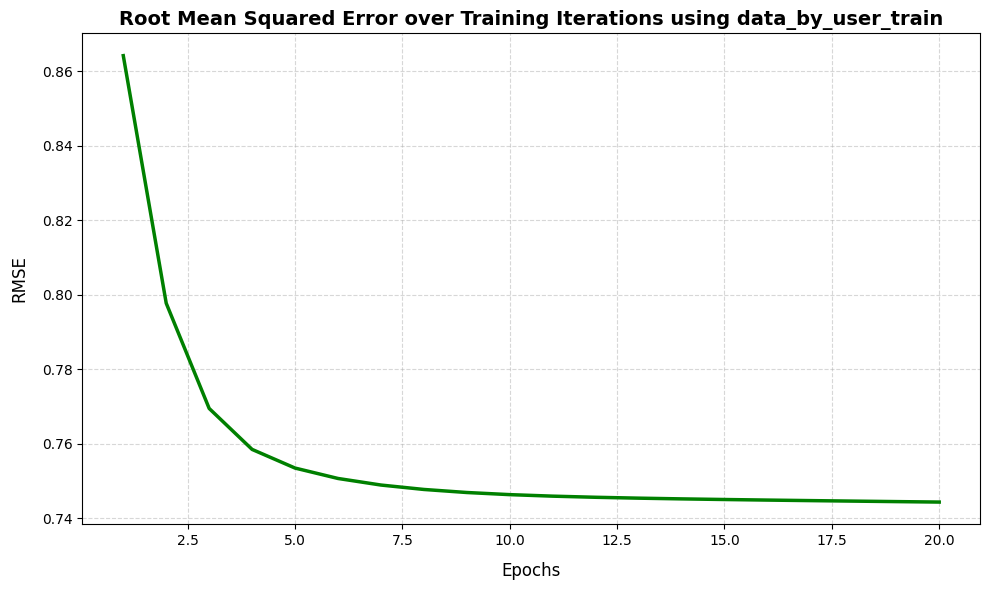

In [ ]:
# Root mean Squared error with embeddings
plt.figure(figsize=(10,6))

plt.plot(iterations, rmse_train_list, color='g', linewidth=2.5)

plt.grid(True, linestyle='--', alpha=0.5)
plt.title("Root Mean Squared Error over Training Iterations using data_by_user_train", fontsize=14, fontweight="bold")
plt.xlabel("Epochs", fontsize=12, labelpad=10)
plt.ylabel("RMSE", fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

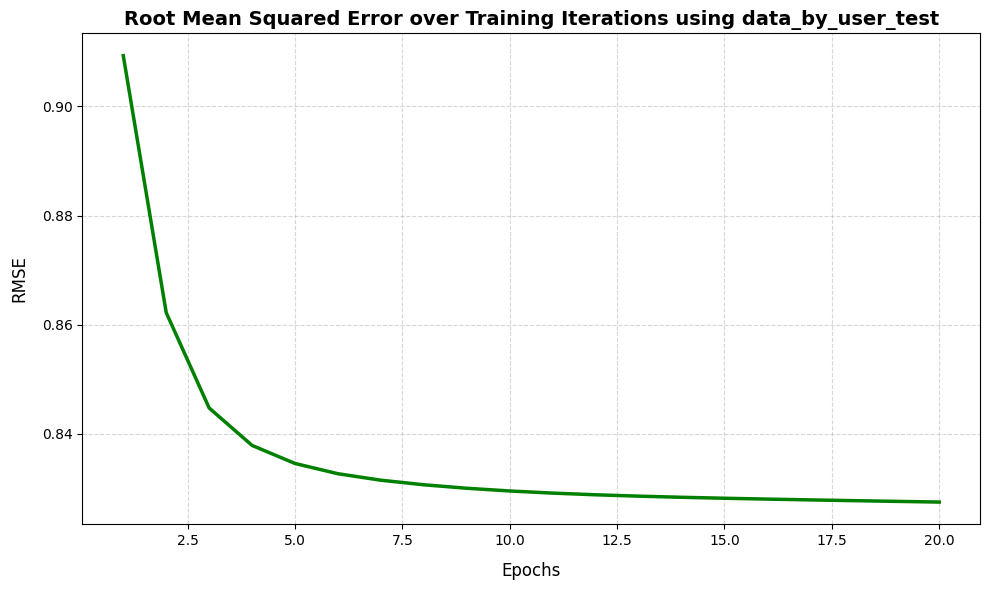

In [ ]:
# Plotting the root mean squared error over data_by_user_test
plt.figure(figsize=(10,6))

plt.plot(iterations, rmse_test_list, color='g', linewidth=2.5)

plt.grid(True, linestyle='--', alpha=0.5)
plt.title("Root Mean Squared Error over Training Iterations using data_by_user_test", fontsize=14, fontweight="bold")
plt.xlabel("Epochs", fontsize=12, labelpad=10)
plt.ylabel("RMSE", fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
np.linalg.inv(np.identity(3) * 2)

array([[0.5, 0. , 0. ],
       [0. , 0.5, 0. ],
       [0. , 0. , 0.5]])

In [ ]:
# help(np.outer)

In [ ]:
# k=23
# np.zeros((k,k))

Practical 4
Using Model over all 32M dataset

In [ ]:
# MAP user to index and vice versa (32M)
user_32m_dict = {}
index_user_32m_list = []

ratings_row = ratings[:, 0]
ratings_col = ratings[:, 1]

for user_id in ratings_row:
  if user_id not in user_32m_dict:

    next_index= len(index_user_32m_list)

    user_32m_dict[user_id] = next_index

    index_user_32m_list.append(user_id)

In [ ]:
item_32m_dict = {}
index_item_32m_list = []

for item_id in ratings_col:
  if item_id not in item_32m_dict:

    next_item_index = len(index_item_32m_list)

    item_32m_dict[item_id] = next_item_index

    index_item_32m_list.append(item_id)

In [ ]:
# Split data into train and test set

import random

data_by_user_32m_train = [[] for _ in range(len(index_user_32m_list))]
data_by_user_32m_test = [[] for _ in range(len(index_user_32m_list))]

data_by_item_32m_train = [[] for _ in range(len(index_item_32m_list))]
data_by_item_32m_test = [[] for _ in range(len(index_item_32m_list))]

data_by_32m_user = [[] for _ in range(len(index_user_32m_list))]
data_by_32m_item = [[] for _ in range(len(index_item_32m_list))]

cut_off = 0.8

for row in ratings:
    random_num = random.random()

    user_id = row[0]
    item_id = row[1]
    rating = float(row[2])

    if user_id in user_32m_dict and item_id in item_32m_dict:
        u_idx = user_32m_dict[user_id]
        i_idx = item_32m_dict[item_id]

        data_by_32m_user[u_idx].append((i_idx, rating))
        data_by_32m_item[i_idx].append((u_idx, rating))

        if random_num < cut_off:
            data_by_user_32m_train[u_idx].append((i_idx, rating))
            data_by_item_32m_train[i_idx].append((u_idx, rating))
        else:
            data_by_user_32m_test[u_idx].append((i_idx, rating))
            data_by_item_32m_test[i_idx].append((u_idx, rating))
    else:
        print("Something is wrong!!!")

In [ ]:
# Number of ratings in train and test sets
train_ratings_count = sum(len(user_ratings) for user_ratings in data_by_user_32m_train)
test_ratings_count = sum(len(user_ratings) for user_ratings in data_by_user_32m_test)

print(f"Total users mapped: {len(data_by_user_32m_train):,}")
print(f"Actual ratings in Train set: {train_ratings_count:,}")
print(f"Actual ratings in Test set: {test_ratings_count:,}")

Total users mapped: 200,948
Actual ratings in Train set: 25,600,593
Actual ratings in Test set: 6,399,611


In [ ]:
train_32m_rating = 0
for i in data_by_user_32m_train:
  train_32m_rating += len(i)
print(train_32m_rating)

test_32m_rating = 0
for i in data_by_user_32m_test:
  test_32m_rating += len(i)
print(test_32m_rating)

25600593
6399611


In [ ]:
#Training on all 32m data
M = len(data_by_user_32m_train)
N = len(data_by_item_32m_train)

mean = 0
variance = 1
k= 5

U = np.random.normal(mean, (variance**0.5), size=(M, k))
V = np.random.normal(mean, (variance**0.5), size=(N, k))


lambda_val = 0.5 #precision parameter.  try different values
gamma_val = 0.1 #bias regularizer. try different values
tau_val = 5 #vector regularizer. try different values

rmse_train_32m_list = []
rmse_test_32m_list = []

rmse_32m_list = []
loss_train_func = []
loss_test_func = []

user_biases = np.zeros(M)
item_biases = np.zeros(N)

epochs = 10

for epoch in range(epochs):
  for i in prange(M):
    bias = 0
    item_counter = 0
    for (n,r) in data_by_user_32m_train[i]:
      bias += lambda_val * (r - (np.dot(U[i], V[n]) + item_biases[n]))
      item_counter += 1
    bias = bias / (lambda_val * item_counter + gamma_val)
    user_biases[i] = bias

    #     updating user vector
    # user_vector = np.zeros(k)
    v_squared = np.zeros((k,k))
    v_sum_biases = np.zeros(k)
    for (n,r) in data_by_user_32m_train[i]:
      v_squared += np.outer(V[n], V[n])
      v_sum_biases += V[n] * (r - user_biases[i] - item_biases[n])

    user_vector = np.linalg.inv(lambda_val * v_squared + tau_val*np.identity(k)) @ (lambda_val  * v_sum_biases)
    U[i] = user_vector


  for i in prange(N):
    bias = 0
    item_counter = 0
    for (n,r) in data_by_item_32m_train[i]:
      bias += lambda_val * (r - (np.dot(U[n], V[i]) + user_biases[n]))
      item_counter += 1
    bias = bias / (lambda_val * item_counter + gamma_val)
    item_biases[i] = bias

    # undating item vector
    u_squared = np.zeros((k,k))
    u_sum_biases = np.zeros(k)
    for (n,r) in data_by_item_32m_train[i]:
      u_squared += np.outer(U[n], U[n])
      u_sum_biases += U[n] * (r - user_biases[n] - item_biases[i])
    item_vector = np.linalg.inv(lambda_val * u_squared + tau_val*np.identity(k)) @ (lambda_val  * u_sum_biases)
    V[i] = item_vector

  train_user_error = 0
  for i in range(M):
    for (n,r) in data_by_user_32m_train[i]:
      train_user_error += (r - np.dot(U[i], V[n]) -  user_biases[i] - item_biases[n])**2
    user_train_loss = (((lambda_val/2) * train_user_error) + ((tau_val/2)* np.sum(U**2)) + ((tau_val/2)* np.sum(V**2)) +  ((gamma_val/2) * np.sum(user_biases**2)) + ((gamma_val/2) * np.sum(item_biases**2)))

  test_user_error = 0
  for i in range(M):
    for (n,r) in data_by_user_32m_test[i]:
      test_user_error += (r - np.dot(U[i], V[n]) - user_biases[i] - item_biases[n])**2
    # user_test_loss = (((lambda_val/2) * test_user_error) + ((gamma_val/2) * np.sum(user_biases**2)) + ((gamma_val/2) * np.sum(item_biases**2)))

  # print(user_train_loss)
  loss_train_func.append(user_train_loss)


  # print(user_test_loss)
  # loss_test_func.append(user_test_loss)

  # This is the root mean square for my train and test set
  rmse_train = (train_user_error/train_32m_rating)**0.5
  rmse_test = (test_user_error/test_32m_rating)**0.5


  print(f"Epochs {epoch+1} | Loss: {user_train_loss: .4f} | RMSE Train: {rmse_train: .3f} | RMSE Test: {rmse_test :.3f}")

  # rmse_test = (test_user_error/test_rating)**0.5


  rmse_train_32m_list.append(rmse_train)
  rmse_test_32m_list.append(rmse_test)

  # print(rmse_train)
  # print(rmse_test)


# print(loss_func)
# print(rmse_list)

In [ ]:
#Save embeddings
np.savez_compressed("my_ratings.npz", U=U,V=V,user_biases=user_biases, item_biases=item_biases, loss_train_func=np.array(loss_train_func), rmse_train_32m_list=np.array(rmse_train_32m_list), rmse_test_32m_list=np.array(rmse_test_32m_list))

In [ ]:
with np.load("my_ratings.npz") as data:
  U = data["U"]
  V = data["V"]
  user_biases = data["user_biases"]
  item_biases = data["item_biases"]

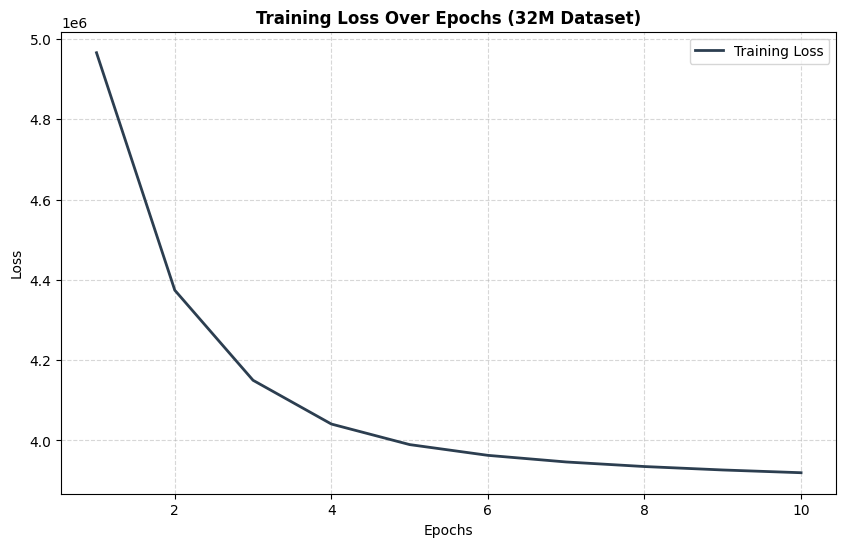

In [ ]:
with np.load("my_ratings.npz") as data:
    loss_train_func = data["loss_train_func"]
    rmse_train_32m_list = data["rmse_train_32m_list"]
    rmse_test_32m_list = data["rmse_test_32m_list"]

epochs_range = range(1, len(loss_train_func) + 1)

plt.figure(figsize=(10, 6))

plt.plot(epochs_range, loss_train_func, color='#2C3E50', linewidth=2, label='Training Loss')
plt.title('Training Loss Over Epochs (32M Dataset)', fontsize=12, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.show()

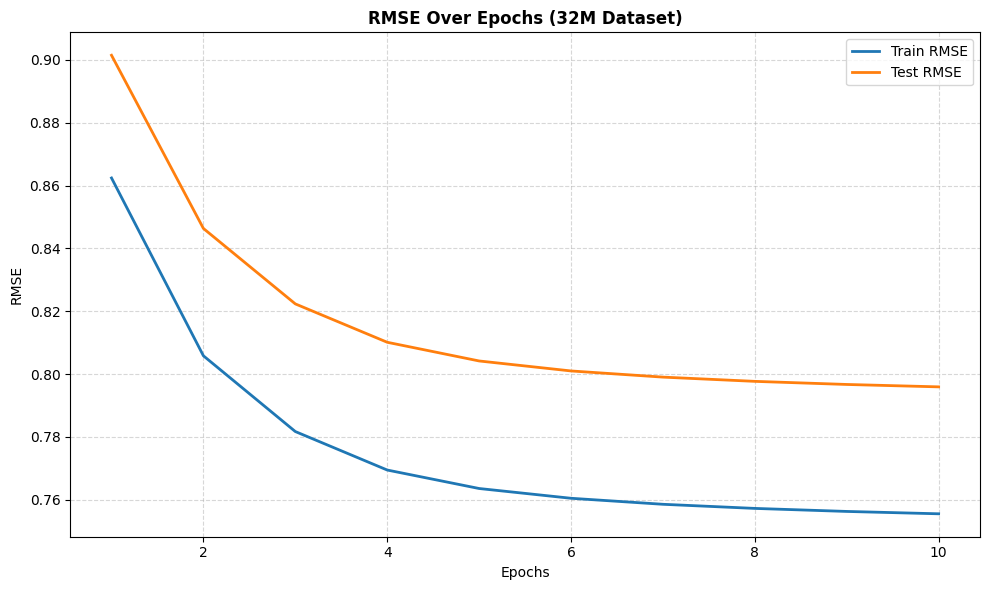

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(epochs_range, rmse_train_32m_list, linewidth=2, label='Train RMSE')
plt.plot(epochs_range, rmse_test_32m_list, linewidth=2, label='Test RMSE')
plt.title('RMSE Over Epochs (32M Dataset)', fontsize=12, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('RMSE')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
#Create a dummy user
dummy_user = [[(1, 5.0)]]

u_ = np.random.normal(mean, (variance**0.5), size=(1, k))
u_bias = np.zeros(1)

epochs = 5
for epoch in range(5):
  for i in range(len(dummy_user)):
    bias = 0
    item_counter = 0
    for (n,r) in dummy_user[i]:
      # Corrected u_(i) to u_[i]
      bias += lambda_val * (r - (np.dot(u_[i], V[n]) + item_biases[n]))
      item_counter += 1
    bias = bias / (lambda_val * item_counter + gamma_val)
    u_bias[i] = bias

    #     updating user vector
    # user_vector = np.zeros(k)
    v_squared = np.zeros((k,k))
    v_sum_biases = np.zeros(k)
    for (n,r) in dummy_user[i]:
      v_squared += np.outer(V[n], V[n])
      v_sum_biases += V[n] * (r - u_bias[i] - item_biases[n])

    u_vector = np.linalg.inv(lambda_val * v_squared + tau_val*np.identity(k)) @ (lambda_val  * v_sum_biases)
    u_[i] = u_vector

  print(u_bias)
  print(u_vector)

[5.12462146]
[0.01305889 0.02132462 0.0081625  0.01146028 0.00624082]
[4.20277309]
[-0.05119623 -0.08360128 -0.03200034 -0.04492902 -0.02446658]
[3.76789833]
[-0.08150809 -0.13309926 -0.05094684 -0.07153023 -0.03895256]
[3.56274956]
[-0.09580747 -0.15644954 -0.05988471 -0.08407914 -0.04578621]
[3.46597224]
[-0.10255309 -0.16746486 -0.06410108 -0.08999899 -0.04900993]


In [ ]:
# 1. Recommendations for a Dummy User who rated Item Index 110 (e.g., Braveheart/Star Wars) with 5.0
dummy_rating = [[(110, 5.0)]]

u_dummy = np.random.normal(0, 1, size=(1, k))
u_bias_dummy = np.zeros(1)

# Train dummy user latent vector and bias
for epoch in range(5):
    bias = 0
    for (n, r) in dummy_rating[0]:
        bias += lambda_val * (r - (np.dot(u_dummy[0], V[n]) + item_biases[n]))
    u_bias_dummy[0] = bias / (lambda_val * len(dummy_rating[0]) + gamma_val)

    v_squared = np.zeros((k, k))
    v_sum_biases = np.zeros(k)
    for (n, r) in dummy_rating[0]:
        v_squared += np.outer(V[n], V[n])
        v_sum_biases += V[n] * (r - u_bias_dummy[0] - item_biases[n])
    u_dummy[0] = np.linalg.inv(lambda_val * v_squared + tau_val * np.identity(k)) @ (lambda_val * v_sum_biases)

# Calculate scores for all items
scores = []
for n in range(N):
    predicted_rating = np.dot(u_dummy[0], V[n]) + u_bias_dummy[0] + item_biases[n]
    scores.append((n, predicted_rating))

# Display top 5 recommendations
top_recommendations = sorted(scores, key=lambda x: x[1], reverse=True)[:5]
print("=== Top 5 Recommendations for Dummy User (Liked Item 110) ===")
for rank, (item_idx, score) in enumerate(top_recommendations, 1):
    print(f"Rank {rank} | Item Index: {item_idx} | Predicted Rating: {score:.4f}")

# 2. Find and Show Polarizing Movies (Unusually long latent vectors V)
vector_magnitudes = np.linalg.norm(V, axis=1)
polarizing_indices = np.argsort(vector_magnitudes)[::-1][:5]

print("\n=== Top 5 Most Polarizing Movies (Largest Latent Vector Magnitudes) ===")
for rank, idx in enumerate(polarizing_indices, 1):
    print(f"Rank {rank} | Item Index: {idx} | Vector Magnitude (L2-norm): {vector_magnitudes[idx]:.4f}")

In [ ]:
score_for_item[]=